In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import ipywidgets as widgets

df = pd.read_csv(r"D:\dataset\covid_19_clean_complete.csv")

# Column rename aur date convert
df = df.rename(columns={"Country/Region": "Country"})
df["Date"] = pd.to_datetime(df["Date"])

# Cleaning
df = df.drop_duplicates()
df["Province/State"] = df["Province/State"].fillna("Unknown")

num_cols = ["Confirmed", "Deaths", "Recovered", "Active"]
df[num_cols] = df[num_cols].fillna(0)
df = df[(df[num_cols] >= 0).all(axis=1)]   # negative values hatao

print(df.shape)
print(df.isnull().sum())

(49050, 10)
Province/State    0
Country           0
Lat               0
Long              0
Date              0
Confirmed         0
Deaths            0
Recovered         0
Active            0
WHO Region        0
dtype: int64


In [6]:
def get_daily(data):
    g = data.groupby("Date")[["Confirmed", "Deaths", "Recovered"]].sum().sort_index()
    daily = g.diff().fillna(g.iloc[0])   # cumulative -> daily
    return daily.clip(lower=0)           # data corrections se negative aaye to 0

daily = get_daily(df)       # poori duniya ka
print(daily.tail())

            Confirmed  Deaths  Recovered
Date                                    
2020-07-23   282756.0  9966.0   169714.0
2020-07-24   281164.0  6144.0   228736.0
2020-07-25   255545.0  4867.0   219038.0
2020-07-26   204606.0  4104.0   134721.0
2020-07-27   228689.0  5415.0   174623.0


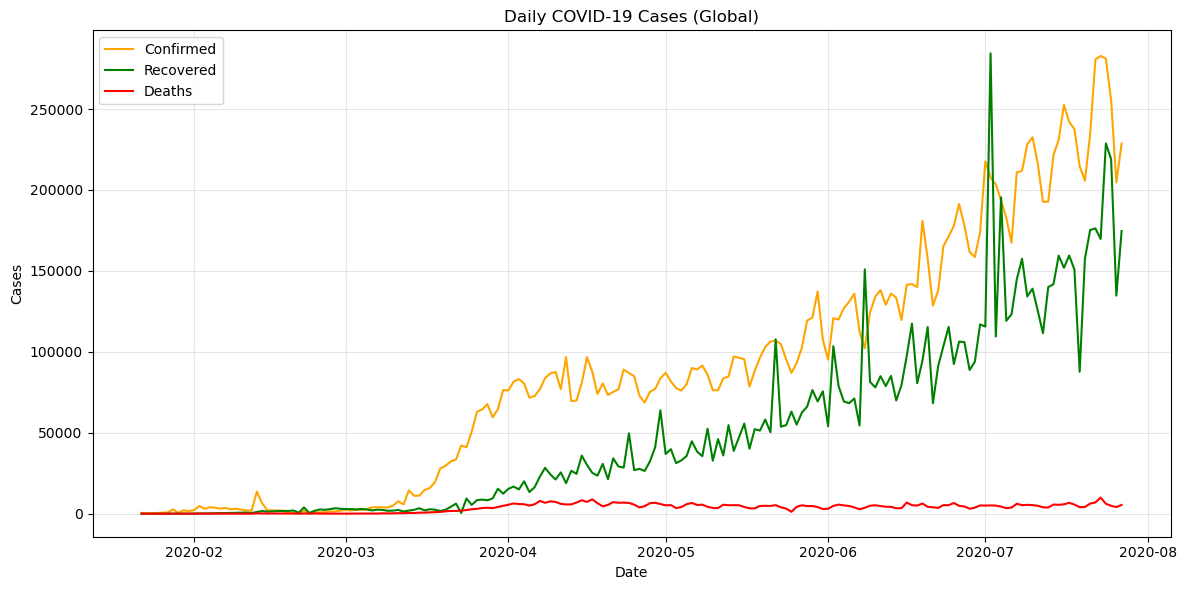

In [7]:
plt.figure(figsize=(12, 6))
plt.plot(daily.index, daily["Confirmed"], label="Confirmed", color="orange")
plt.plot(daily.index, daily["Recovered"], label="Recovered", color="green")
plt.plot(daily.index, daily["Deaths"], label="Deaths", color="red")
plt.title("Daily COVID-19 Cases (Global)")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("daily_line.png")
plt.show()

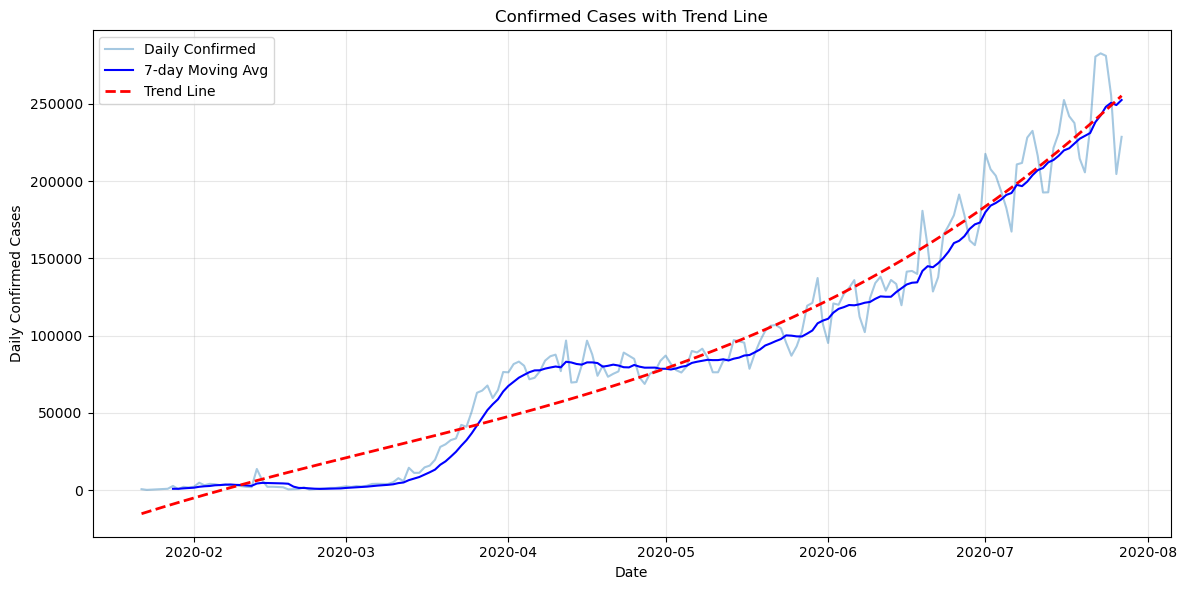

In [8]:
x = np.arange(len(daily))
y = daily["Confirmed"].values

# Polynomial trend (degree 3)
coeff = np.polyfit(x, y, 3)
trend = np.poly1d(coeff)(x)

# 7-day moving average
ma7 = daily["Confirmed"].rolling(7).mean()

plt.figure(figsize=(12, 6))
plt.plot(daily.index, y, alpha=0.4, label="Daily Confirmed")
plt.plot(daily.index, ma7, color="blue", label="7-day Moving Avg")
plt.plot(daily.index, trend, color="red", linestyle="--", linewidth=2, label="Trend Line")
plt.title("Confirmed Cases with Trend Line")
plt.xlabel("Date")
plt.ylabel("Daily Confirmed Cases")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("trend_line.png")
plt.show()

In [9]:
countries = ["All"] + sorted(df["Country"].unique())
all_dates = pd.date_range(df["Date"].min(), df["Date"].max())

def dashboard(country, date_range):
    data = df if country == "All" else df[df["Country"] == country]
    d = get_daily(data).loc[date_range[0]:date_range[1]]
    d["Trend (7-day avg)"] = d["Confirmed"].rolling(7, min_periods=1).mean()

    fig = px.line(d, x=d.index, y=["Confirmed", "Recovered", "Deaths", "Trend (7-day avg)"],
                  title=f"Daily COVID-19 Cases - {country}",
                  labels={"value": "Cases", "Date": "Date", "variable": "Type"})
    fig.show()

widgets.interact(
    dashboard,
    country=widgets.Dropdown(options=countries, value="All", description="Country"),
    date_range=widgets.SelectionRangeSlider(
        options=[(d.strftime("%d-%b-%Y"), d) for d in all_dates],
        index=(0, len(all_dates) - 1),
        description="Dates",
        layout=widgets.Layout(width="700px"),
    ),
);

interactive(children=(Dropdown(description='Country', options=('All', 'Afghanistan', 'Albania', 'Algeria', 'An…

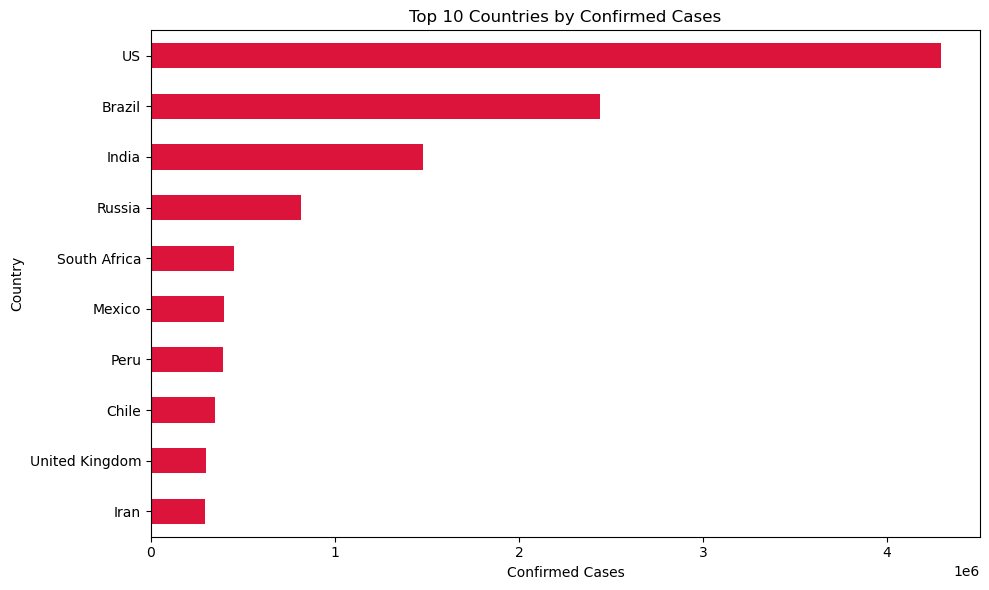

In [10]:
latest = df[df["Date"] == df["Date"].max()]
top10 = latest.groupby("Country")["Confirmed"].sum().nlargest(10).sort_values()

top10.plot(kind="barh", figsize=(10, 6), color="crimson")
plt.title("Top 10 Countries by Confirmed Cases")
plt.xlabel("Confirmed Cases")
plt.tight_layout()
plt.savefig("top10.png")
plt.show()

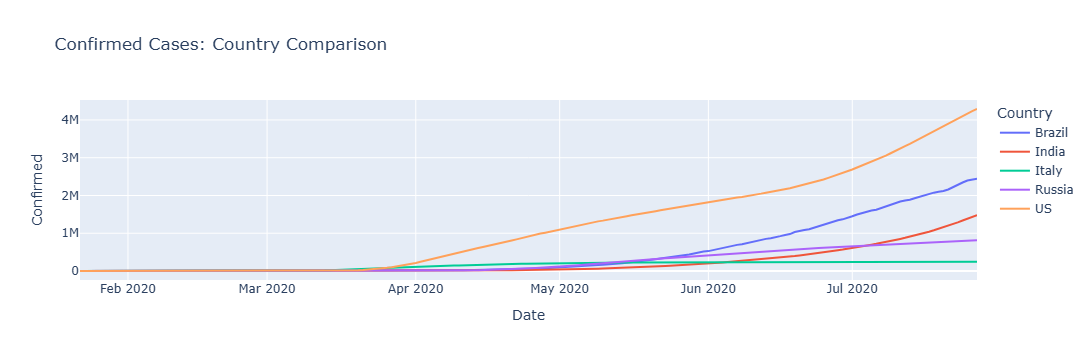

In [11]:
countries_to_compare = ["India", "US", "Brazil", "Russia", "Italy"]
comp = df[df["Country"].isin(countries_to_compare)]
comp = comp.groupby(["Date", "Country"])["Confirmed"].sum().reset_index()

fig = px.line(comp, x="Date", y="Confirmed", color="Country",
              title="Confirmed Cases: Country Comparison")
fig.show()

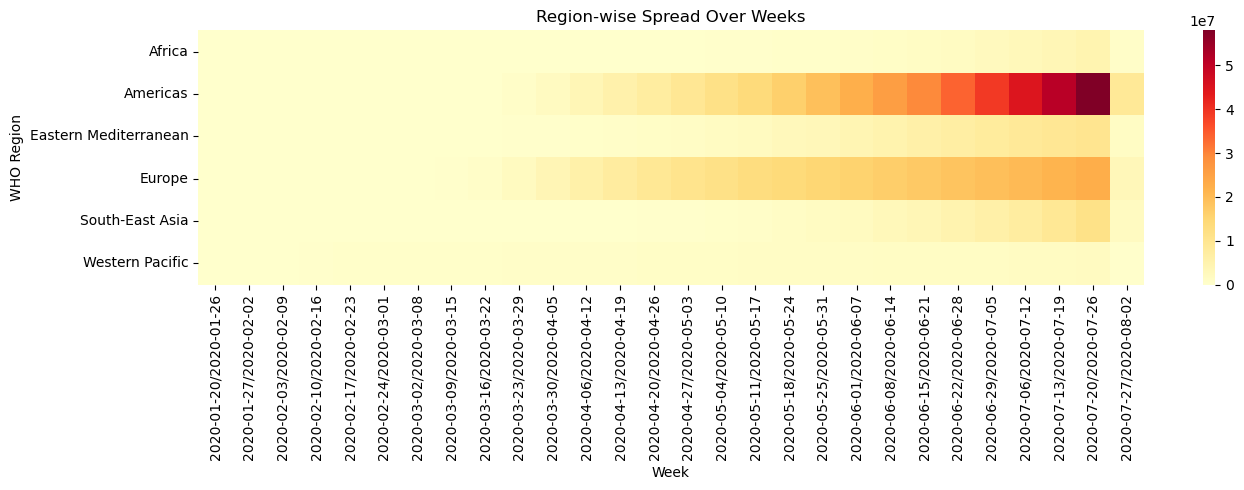

In [12]:
import seaborn as sns

df["Week"] = df["Date"].dt.to_period("W").astype(str)
heat = df.groupby(["WHO Region", "Week"])["Confirmed"].sum().reset_index()
heat = heat.pivot(index="WHO Region", columns="Week", values="Confirmed")

plt.figure(figsize=(14, 5))
sns.heatmap(heat, cmap="YlOrRd")
plt.title("Region-wise Spread Over Weeks")
plt.tight_layout()
plt.show()

C:\Users\DELL PC\AppData\Local\Temp\ipykernel_4104\1309001523.py:5: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



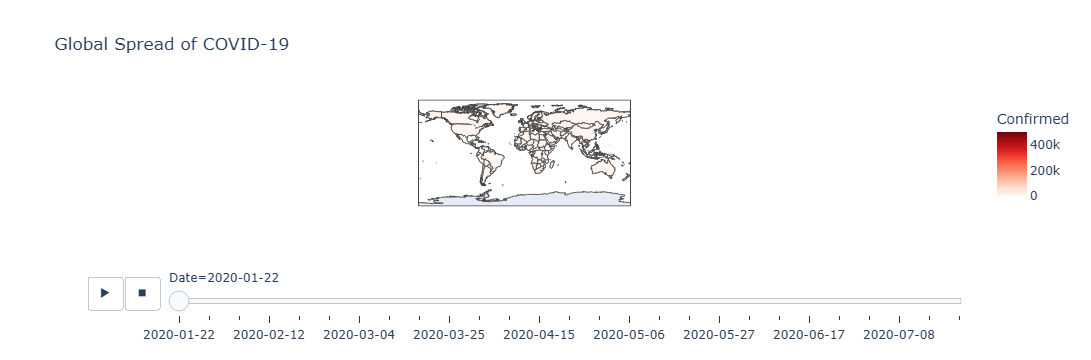

In [14]:
map_df = df.groupby(["Date", "Country"])["Confirmed"].sum().reset_index()
map_df["Date"] = map_df["Date"].dt.strftime("%Y-%m-%d")
map_df = map_df[map_df["Date"].isin(sorted(map_df["Date"].unique())[::7])]  # har 7 din, taaki fast chale

fig = px.choropleth(map_df, locations="Country", locationmode="country names",
                    color="Confirmed", animation_frame="Date",
                    color_continuous_scale="Reds", range_color=(0, 500000),
                    title="Global Spread of COVID-19")
fig.show()

In [15]:
print("Thank you")

Thank you
